# Optimum Progress and Calibration

For weeks 2 and 3, this notebook compares the previous best-so-far, the expected best-so-far saved in `predictions.json`, and the observed best-so-far. It also checks how well the expected outputs match the observed outputs.

In [1]:
%matplotlib inline
from pathlib import Path
import json

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bayesian_bbo import FUNCTION_SPECS, load_observations
from bayesian_bbo.visualisation import plot_calibration, plot_optimum_progress

WEEKS = (2, 3)
FUNCTION_IDS = tuple(FUNCTION_SPECS)

data_candidates = [Path("../../data"), Path("data"), Path("../data")]
matches = [path.resolve() for path in data_candidates if (path / "function_1").is_dir()]
if not matches:
    raise FileNotFoundError("Could not find the data directory from the notebook working directory.")
data_root: Path = matches[0]
print(f"Data root: {data_root}")

Data root: /home/pabloncho/repositories/bayesian-bbo/data


## 1. Load Best-so-far Values and Residuals

In [2]:
previous_best = np.empty((len(FUNCTION_IDS), len(WEEKS)))
expected_best = np.empty_like(previous_best)
observed_best = np.empty_like(previous_best)
residuals = {function_id: [] for function_id in FUNCTION_IDS}

for week_index, week in enumerate(WEEKS):
    predictions_path = data_root / "weekly_updates" / f"week_{week}" / "predictions.json"
    predictions = json.loads(predictions_path.read_text(encoding="utf-8"))
    for function_index, function_id in enumerate(FUNCTION_IDS):
        before = load_observations(data_root, function_id, up_to_week=week - 1)
        through = load_observations(data_root, function_id, up_to_week=week)
        this_week = through.weeks == week
        mean = through.expected_outputs[this_week]
        std = through.stds[this_week]
        if len(mean) != 1 or not np.isclose(mean[0], predictions["expected_outputs"][function_index]):
            raise ValueError(f"Stored expected output differs from predictions.json: function {function_id}, week {week}")
        if not np.all(std > 0):
            raise ValueError(f"Standard deviation must be positive: function {function_id}, week {week}")

        previous_best[function_index, week_index] = before.best_output
        observed_best[function_index, week_index] = through.best_output
        expected_best[function_index, week_index] = predictions["expected_best_outputs"][function_index]
        residuals[function_id].extend(((through.outputs[this_week] - mean) / std).tolist())

pd.DataFrame(
    {
        f"Week {week} {label}": values[:, week_index]
        for week_index, week in enumerate(WEEKS)
        for label, values in (("previous", previous_best), ("expected", expected_best), ("observed", observed_best))
    },
    index=[f"Function {function_id}" for function_id in FUNCTION_IDS],
).round(4)

,Week 2 previous,Week 2 expected,Week 2 observed,Week 3 previous,Week 3 expected,Week 3 observed
Function 1,0.0000,0.0012,0.0000,0.0000,0.0004,0.0000
Function 2,0.6112,0.6443,0.6112,0.6112,0.6321,0.6112
Function 3,-0.0348,-0.0197,-0.0059,-0.0059,0.0233,-0.0059
Function 4,-4.0255,-3.4646,-3.3364,-3.3364,-2.6195,-1.2696
Function 5,1088.8596,1090.5900,1397.5451,1397.5451,1720.3868,1588.5985
Function 6,-0.7143,-0.6695,-0.7143,-0.7143,-0.4368,-0.4670
Function 7,1.3650,1.3650,1.3650,1.3650,1.3710,2.3677
Function 8,9.5985,9.6188,9.5985,9.5985,9.8809,9.8811


## 2. Optimum Progress

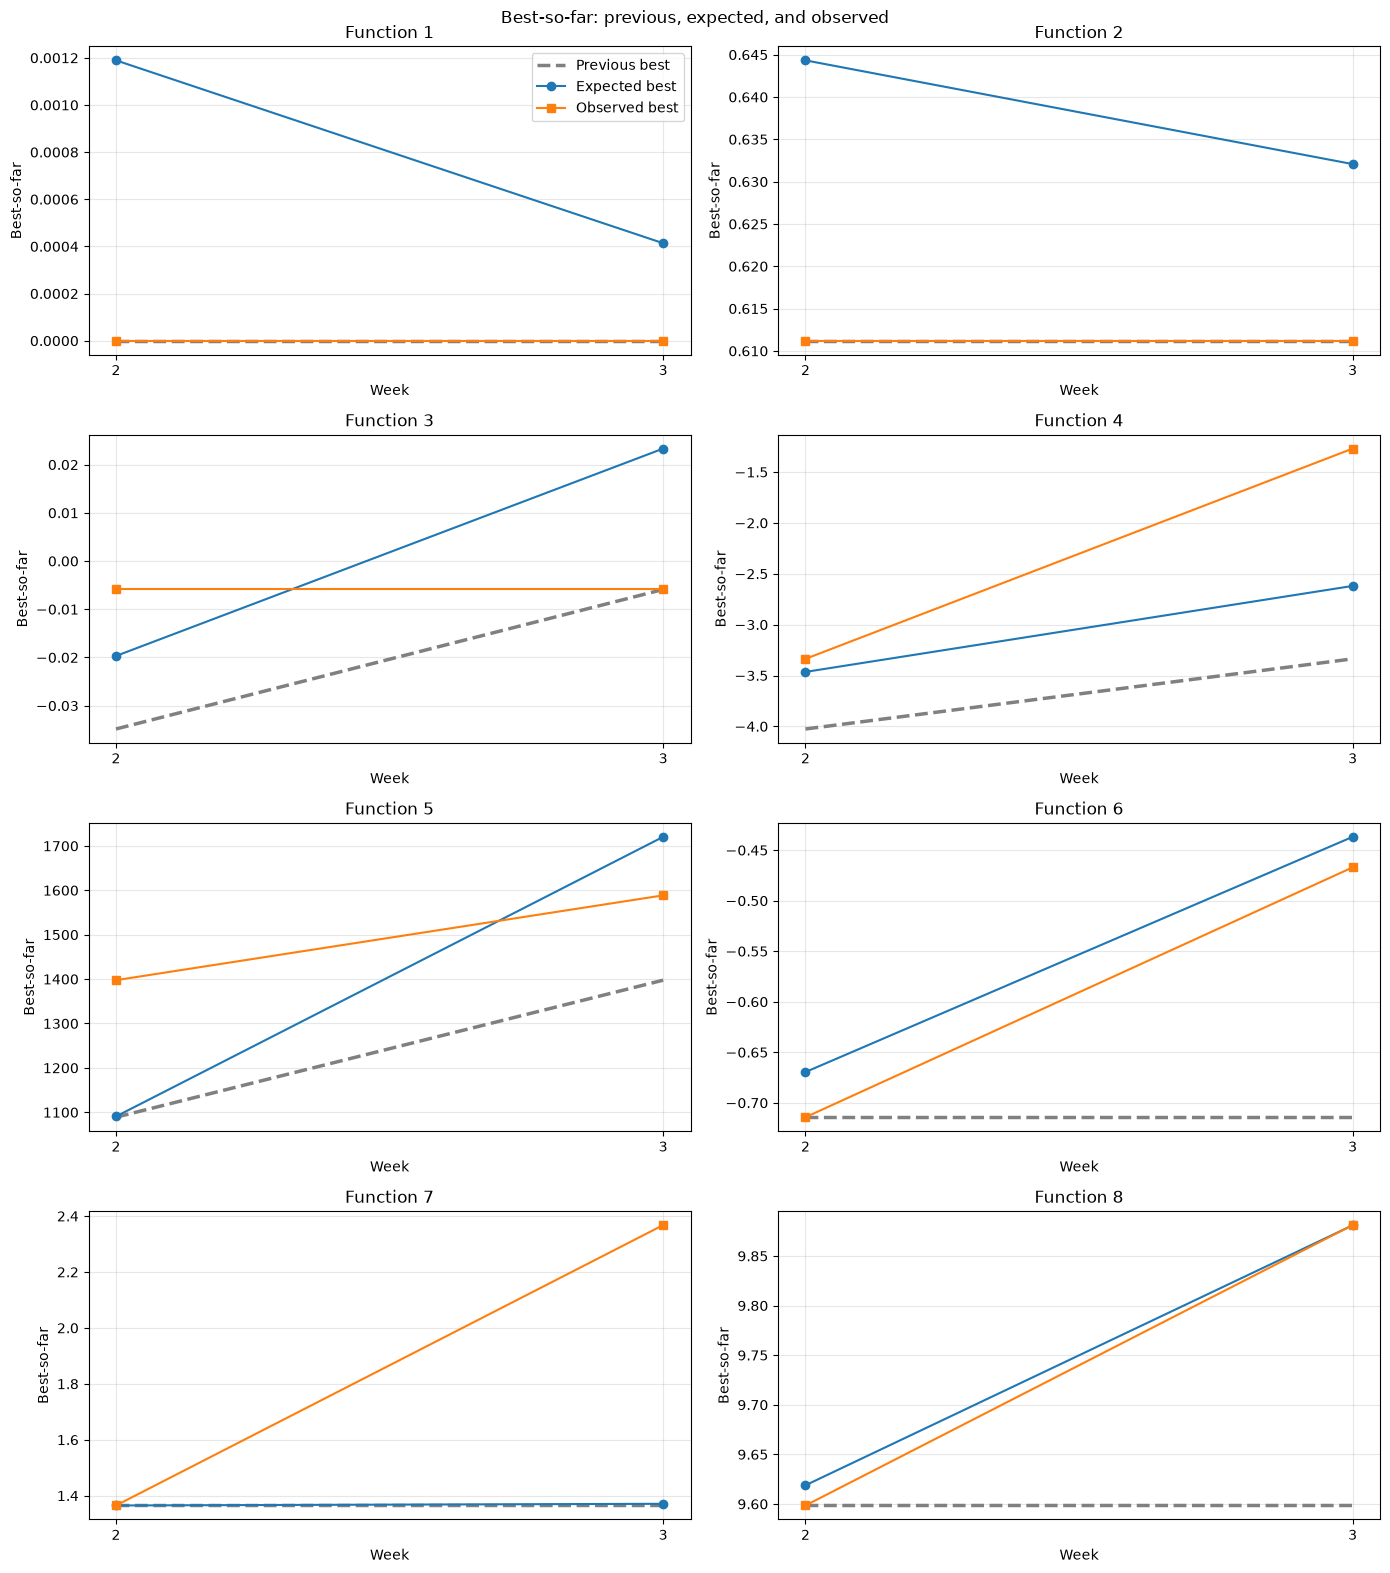

In [3]:
%matplotlib inline
optimum_figure, optimum_axes = plot_optimum_progress(
    WEEKS, FUNCTION_IDS, previous_best, expected_best, observed_best
)
display(optimum_figure)
plt.close(optimum_figure)

## 3. Calibration of Expected Outputs

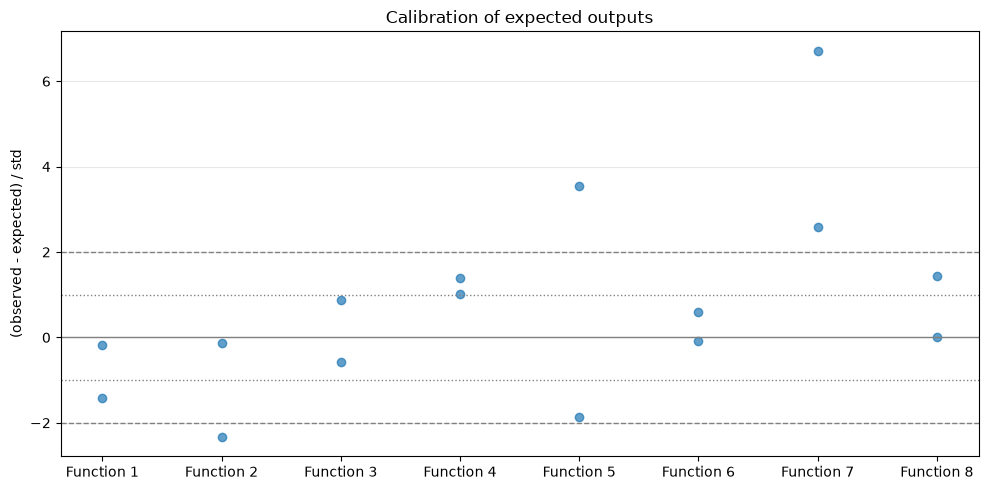

In [4]:
%matplotlib inline
calibration_figure, calibration_ax = plot_calibration(residuals)
display(calibration_figure)
plt.close(calibration_figure)

## Notes

- The expected best-so-far is never below the previous best, because $\mathbb{E}[\max(f(x), f^*)] \ge f^*$.
- Each week has one observation per function, so each observed value is a single sample.
- The residuals are $z = (y - \mu)/\sigma$ for each week's suggested point. With only 16 residuals, values beyond $\pm 2$ are a rough warning, not a conclusion.

## 4. GP Mean, Uncertainty, and Expected Improvement

Use full-domain heatmaps for 2D inputs and coordinate slices through the optimizer's suggested input otherwise. Slices show only observations whose other coordinates match the reference, not projections of off-slice observations.

The shaded band is the pointwise mean +/- 1.96 predictive standard deviations, including the fitted WhiteKernel noise. The true black-box function is unknown, so no true-function curve is drawn. Both plots call `suggest_with_prediction()` for the candidate and `optimizer.predict()` for the plotted mean, uncertainty, and EI, sharing one fitted GP and acquisition configuration. The suggestion maximizes EI over the optimizer's random candidate pool, not the plotted grid or the continuous domain. Off-slice observations are omitted; a slice may therefore contain no observed points.

The example uses the selected Matérn 3/2 kernel, length-scale caps, and per-function EI settings from [the week-2 suggestions notebook](../week_2/06_all_functions_ei_matern32_suggestions.ipynb). `plot_week` is the suggestion week: training uses observations through `plot_week - 1`, excluding that week's result. Normalization, optimizer restarts, and random seed use the same `fit_surrogate` defaults as the suggestion model. Change `plot_function_ids` and `plot_week` below.

In [5]:
from bayesian_bbo import BayesianOptimizer, OptimisationConfig
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel

LENGTH_CAPS = {
    1: 31.622776601683793, 2: 31.622776601683793, 3: 31.622776601683793,
    4: 10.0, 5: 100.0, 6: 31.622776601683793, 7: 31.622776601683793, 8: 100.0,
}
XI_VALUES = {
    1: 0.00010366701219489613, 2: 0.02169598518452902,
    3: 0.008514510271522311, 4: 0.7327808565722272,
    5: 35.75969037053485, 6: 0.046625804381253966,
    7: 0.03342741263225186, 8: 0.09678071263663912,
}


def make_matern_32_kernel(dimension, length_cap):
    return (
        ConstantKernel(1.0, (1e-3, 1e3))
        * Matern(np.ones(dimension), length_scale_bounds=(1e-3, length_cap), nu=1.5)
        + WhiteKernel(1e-5, (1e-8, 1e1))
    )


def plot_gp_2d(optimizer, n=80):
    observations = optimizer.observations
    candidate, _, _, _ = optimizer.suggest_with_prediction()
    grid = np.linspace(0, np.nextafter(1.0, 0.0), n)
    x1, x2 = np.meshgrid(grid, grid)
    points = np.column_stack((x1.ravel(), x2.ravel()))
    mean, std, ei = optimizer.predict(points)
    best = observations.best_input
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
    for ax, values, title in zip(axes, (mean, std, ei), ("GP mean", "Predictive std", "EI")):
        image = ax.pcolormesh(x1, x2, values.reshape(x1.shape), shading="auto")
        fig.colorbar(image, ax=ax)
        ax.scatter(*observations.inputs.T, c="black", edgecolors="white", s=30, label="Observations")
        ax.scatter(*best, c="red", marker="*", s=130, label="Best observed")
        ax.set(title=title, xlabel="x1", ylabel="x2", xlim=(0, 1), ylim=(0, 1))
    axes[0].legend(fontsize=8)
    axes[2].scatter(*candidate, c="red", marker="v", s=70, label="Optimizer suggestion")
    axes[2].legend(fontsize=8)
    return fig, axes


def plot_gp_slices(optimizer, n=200):
    observations = optimizer.observations
    reference, candidate_mean, _, candidate_ei = optimizer.suggest_with_prediction()
    dimension = observations.dimension
    grid = np.linspace(0, np.nextafter(1.0, 0.0), n)
    fig, axes = plt.subplots(
        2, dimension, figsize=(3.5 * dimension, 6), squeeze=False,
        sharex="col", constrained_layout=True,
    )
    for j in range(dimension):
        points = np.tile(reference, (n, 1))
        points[:, j] = grid
        mean, std, ei = optimizer.predict(points)
        other = np.arange(dimension) != j
        on_slice = np.all(np.isclose(observations.inputs[:, other], reference[other]), axis=1)
        top, bottom = axes[:, j]
        top.plot(grid, mean, label="GP mean")
        top.fill_between(grid, mean - 1.96 * std, mean + 1.96 * std, alpha=0.2, label="95% predictive band")
        top.scatter(observations.inputs[on_slice, j], observations.outputs[on_slice], c="black", label="On-slice observations")
        top.axhline(observations.best_output, color="gray", linestyle=":", label="Best observed")
        top.set(title=f"Vary x{j + 1}", ylabel="Output")
        bottom.plot(grid, ei, color="green")
        top.scatter(reference[j], candidate_mean, c="red", marker="v", label="Suggested mean")
        bottom.scatter(reference[j], candidate_ei, c="red", marker="v", label="Optimizer suggestion")
        bottom.set(xlabel=f"x{j + 1}", ylabel="EI", ylim=(0, None))
        for ax in (top, bottom):
            ax.axvline(reference[j], color="gray", linestyle="--")
            ax.set_xlim(0, 1)
    axes[0, 0].legend(fontsize=7)
    axes[1, 0].legend(fontsize=7)
    return fig, axes

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


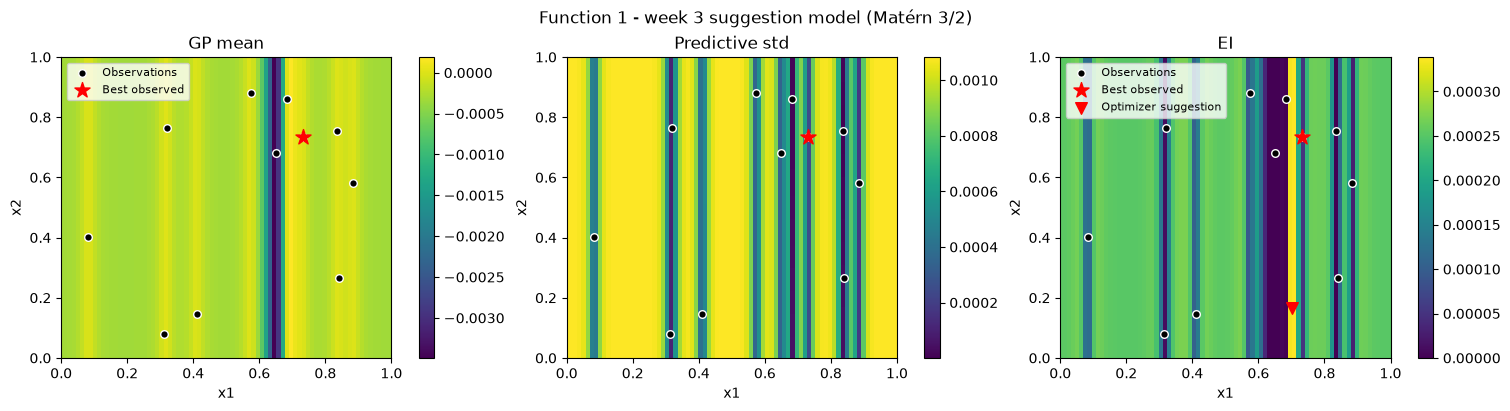

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


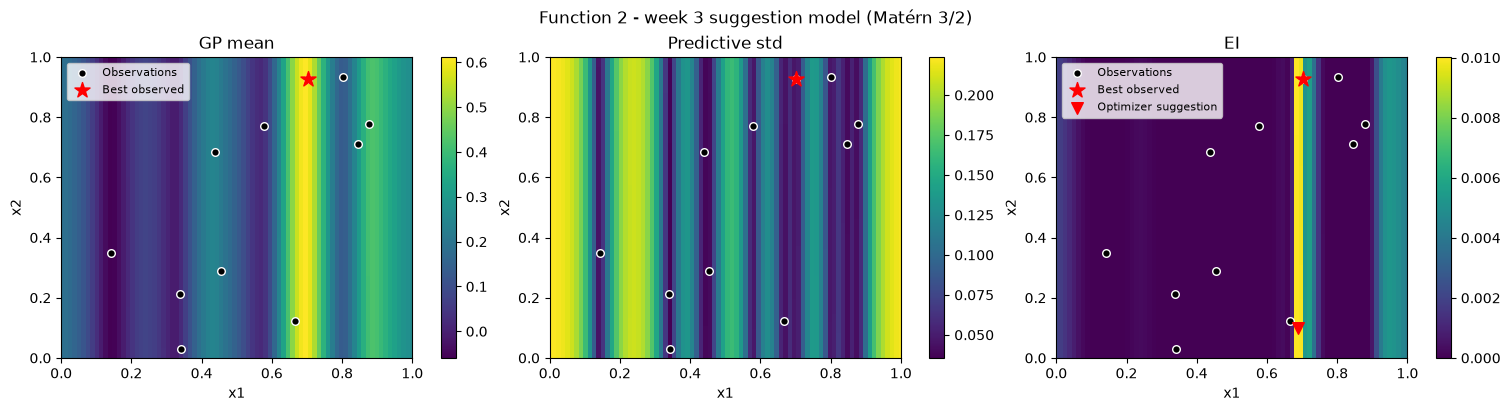

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


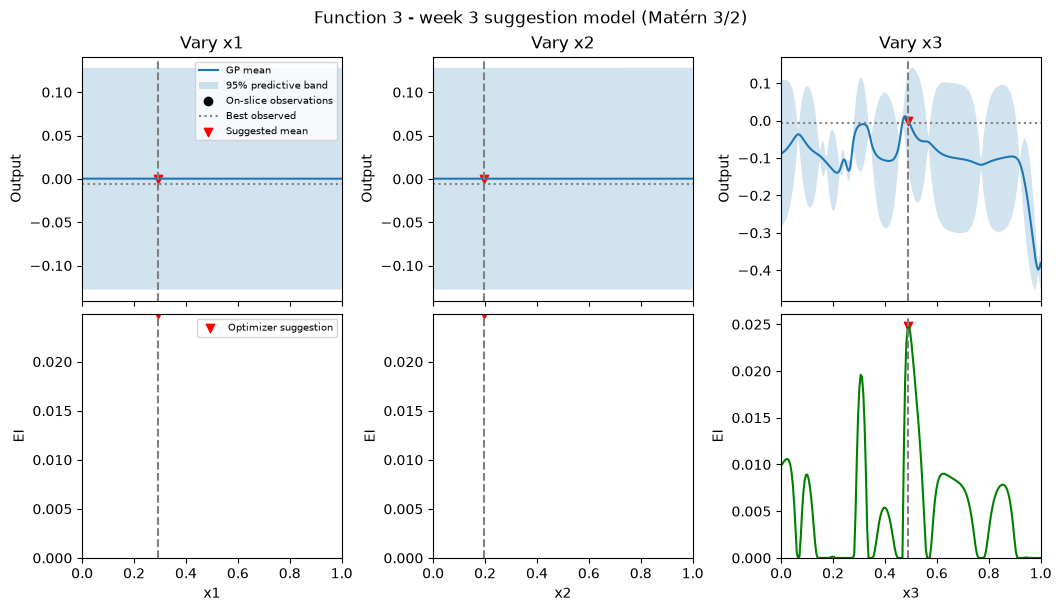

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


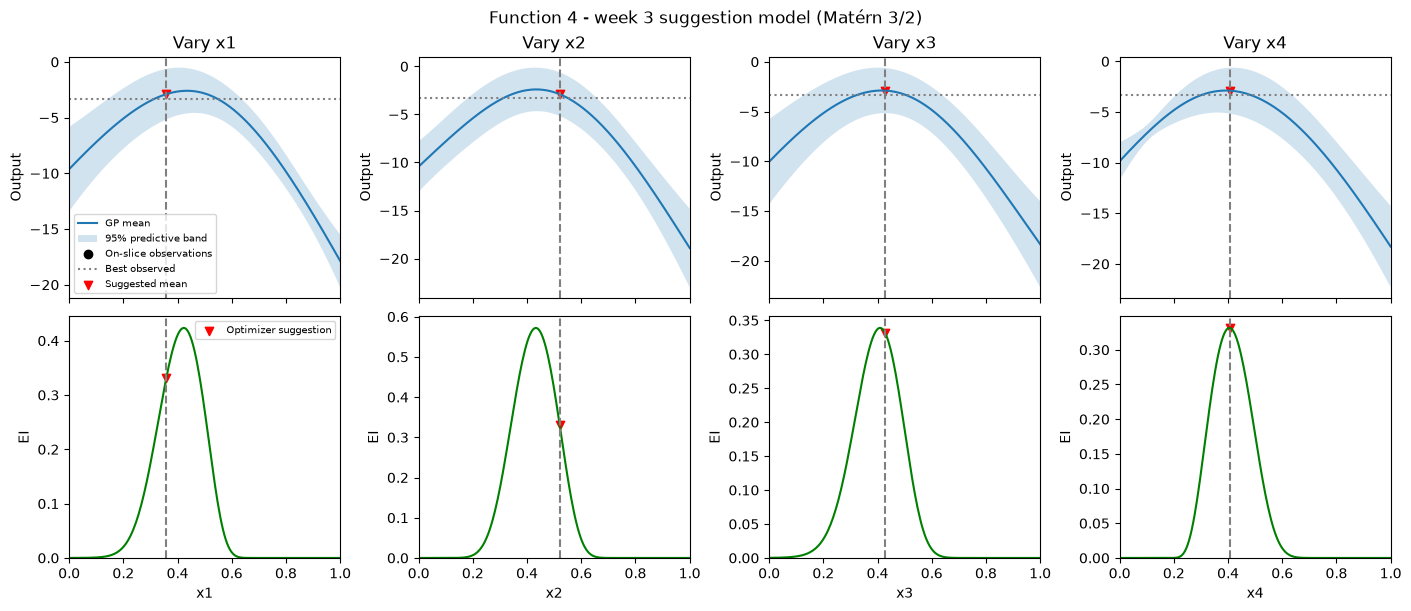

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


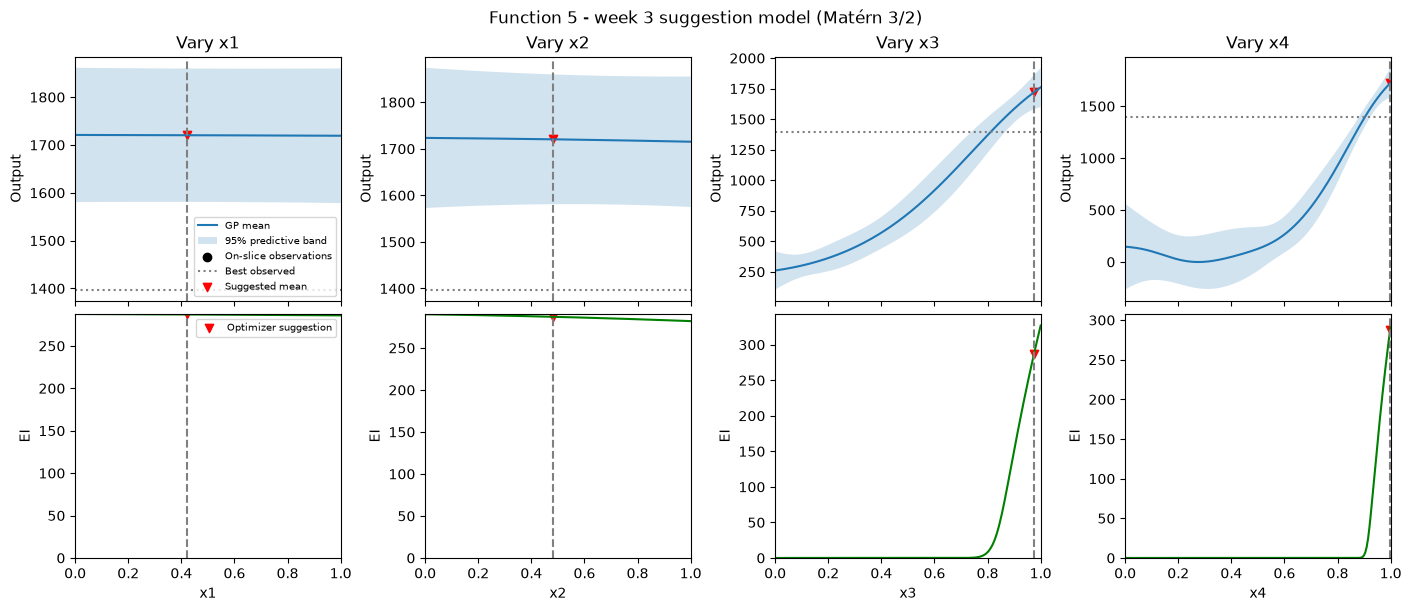

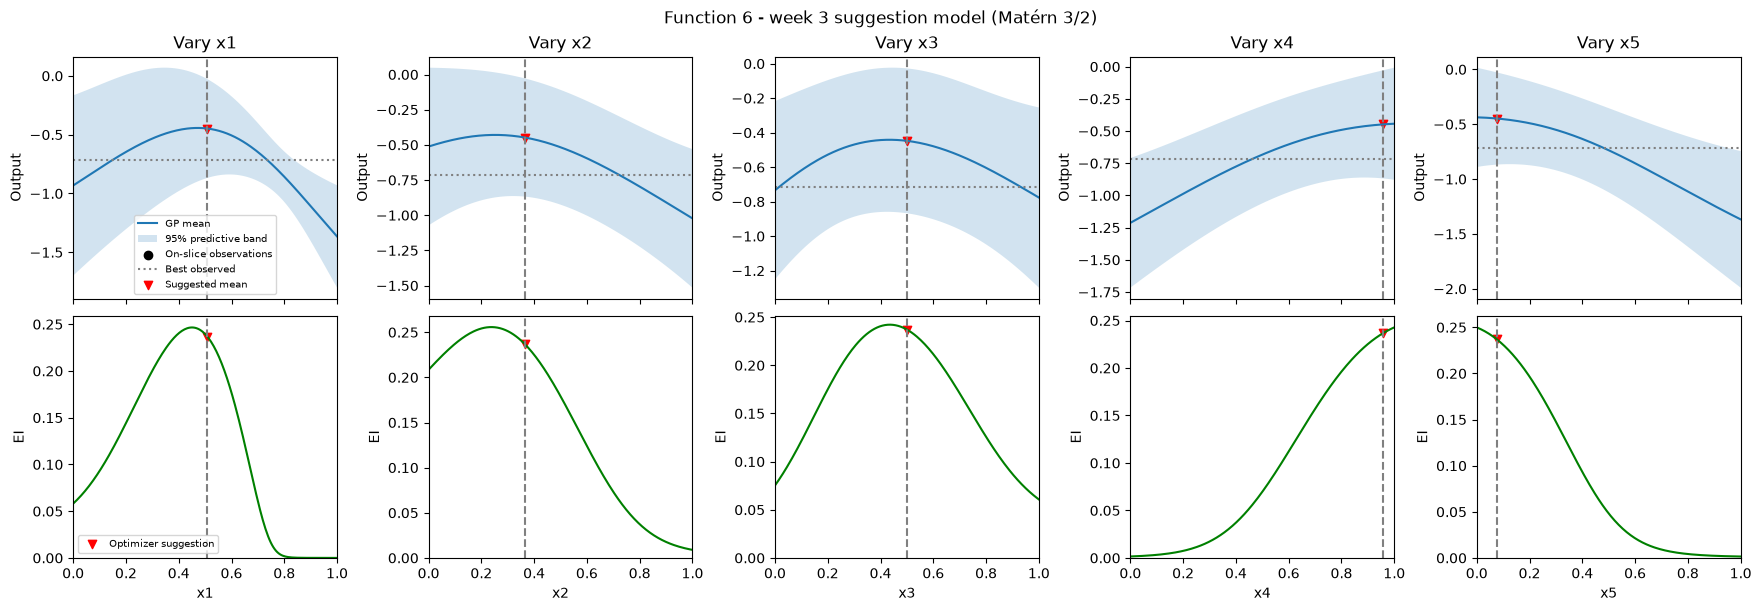

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


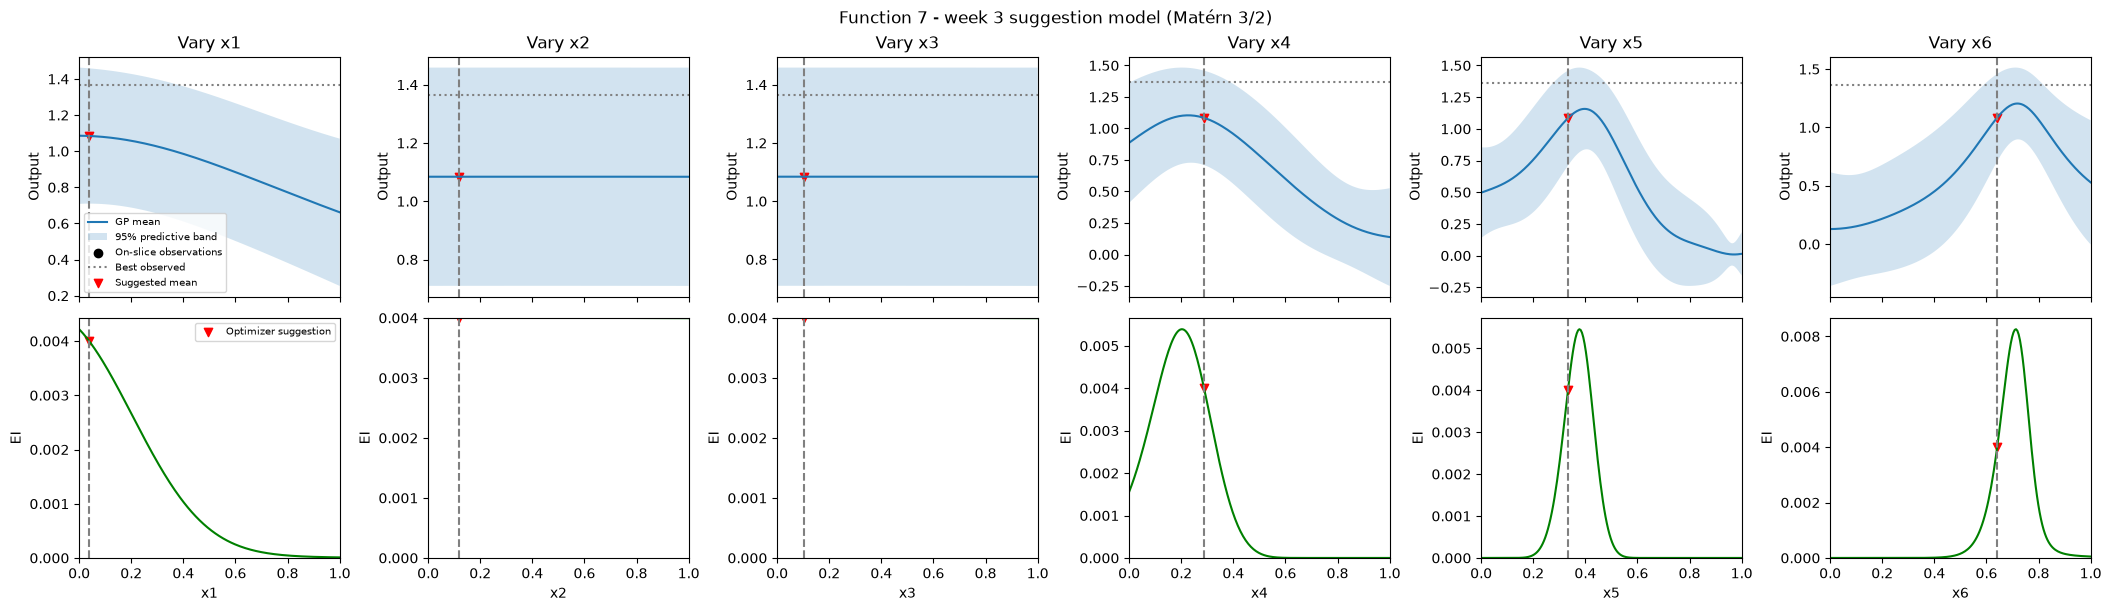

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


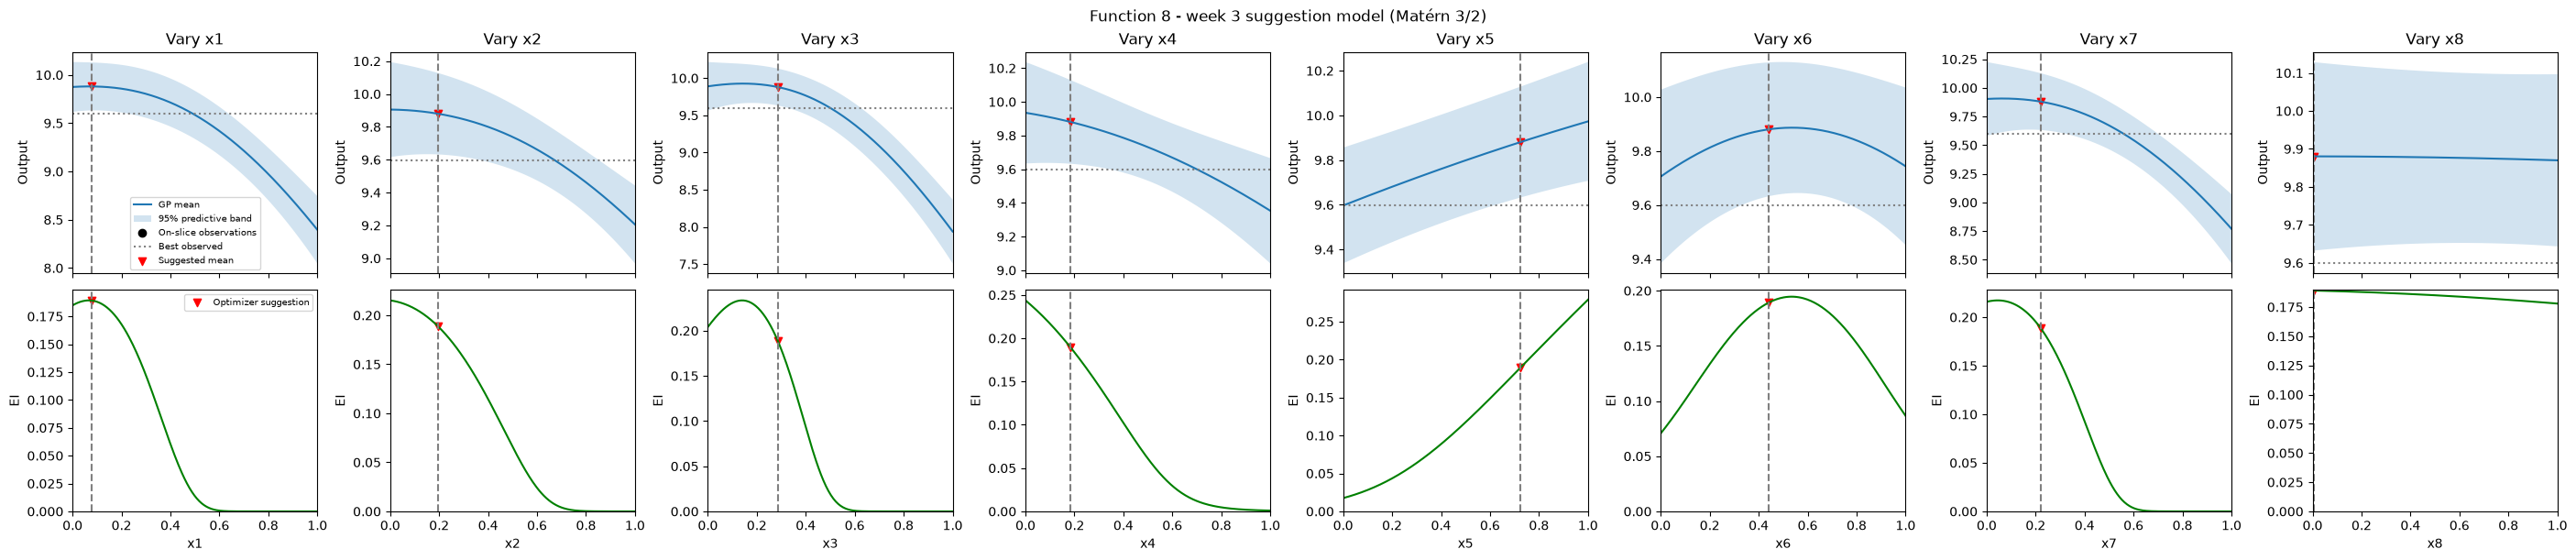

In [6]:
plot_function_ids = (1, 2, 3, 4, 5, 6, 7, 8)
plot_week = max(WEEKS)

for function_id in plot_function_ids:
    observations = load_observations(data_root, function_id, up_to_week=plot_week - 1)
    kernel = make_matern_32_kernel(observations.dimension, LENGTH_CAPS[function_id])
    optimizer = BayesianOptimizer(
        observations, OptimisationConfig(budget=1, kernel=kernel, xi=XI_VALUES[function_id])
    )
    plot = plot_gp_2d if observations.dimension == 2 else plot_gp_slices
    figure, axes = plot(optimizer)
    figure.suptitle(f"Function {function_id} - week {plot_week} suggestion model (Matérn 3/2)")
    display(figure)
    plt.close(figure)